
PDO subtype counts:
HR+ Her2-        25
HR+ Her2+         4
HR- Her2-         1
HR- Her2+         4
HR+ Her2 Equi     1
dtype: int64

Tumor subtype counts:
HR+ Her2-        21
HR+ Her2+         3
HR- Her2-         2
HR+ Her2 Equi     1
dtype: int64


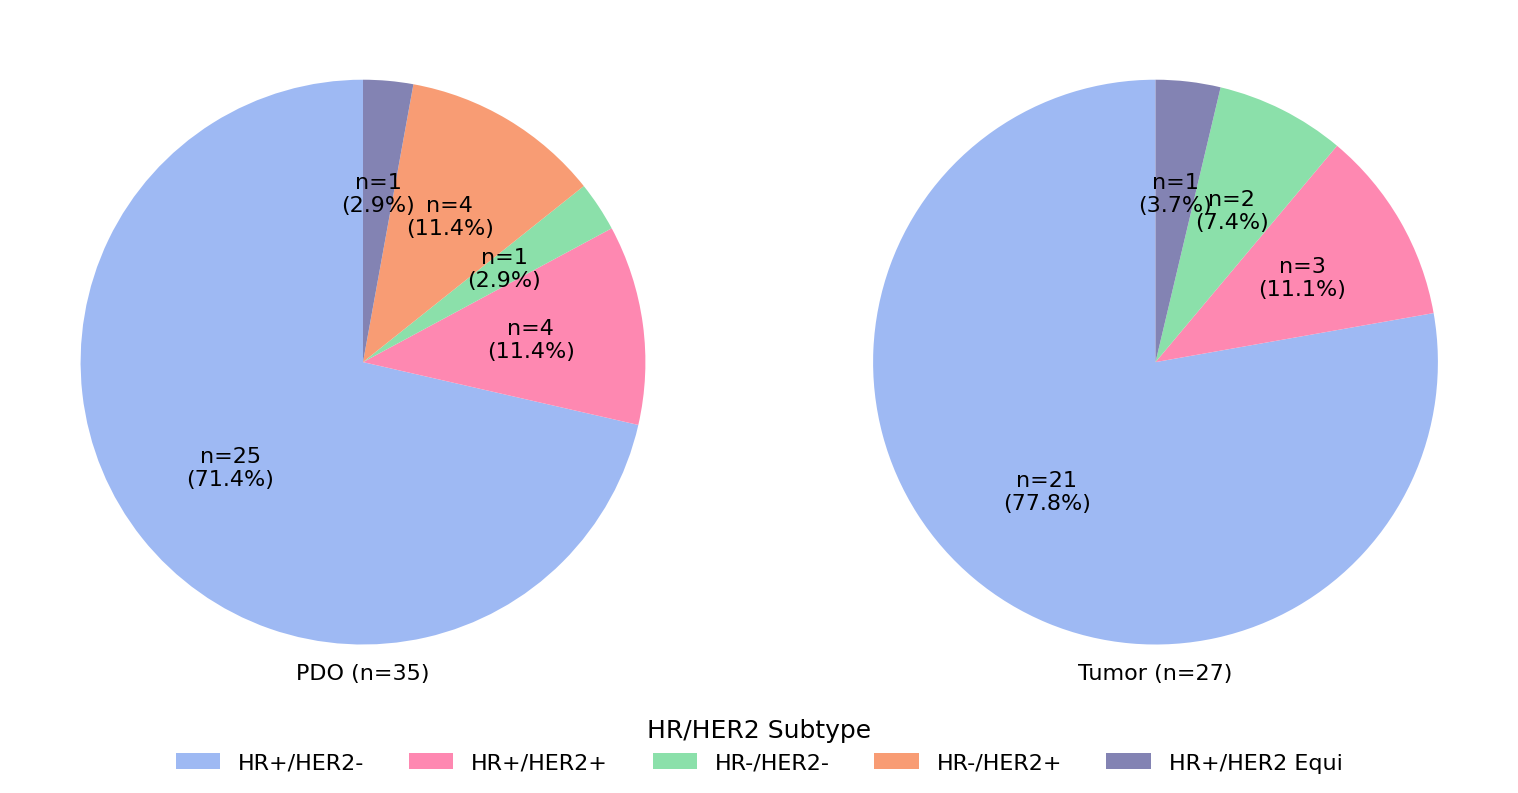


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/HR_HER2_subtype_pie.png
/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/HR_HER2_subtype_pie.pdf


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------
# Load data
# -----------------------------
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Bionano_cohort.csv"
df = pd.read_csv(csv_path)

# Clean whitespace
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.strip()

# -----------------------------
# HR/HER2 subtype columns
# -----------------------------
subtype_cols = [
    "HR+ Her2-",
    "HR+ Her2+",
    "HR- Her2-",
    "HR- Her2+",
    "HR+ Her2 Equi"
]

# Short labels for legend
legend_labels = {
    "HR+ Her2-": "HR+/HER2-",
    "HR+ Her2+": "HR+/HER2+",
    "HR- Her2-": "HR-/HER2-",
    "HR- Her2+": "HR-/HER2+",
    "HR+ Her2 Equi": "HR+/HER2 Equi"
}

# Consistent colors
color_map = {
    "HR+ Her2-": "#9EB9F3",
    "HR+ Her2+": "#FE88B1",
    "HR- Her2-": "#8BE0AA",
    "HR- Her2+": "#F89C74",
    "HR+ Her2 Equi": "#8383B3"
}

# -----------------------------
# Count subtype function
# -----------------------------
def count_subtypes(df_subset):
    counts = {}
    for col in subtype_cols:
        counts[col] = (
            df_subset[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .eq("yes")
            .sum()
        )
    counts = pd.Series(counts)
    counts = counts[counts > 0]
    return counts

# -----------------------------
# Autopct function
# -----------------------------
def autopct_with_counts(values):
    total = sum(values)

    def inner(pct):
        count = int(round(pct * total / 100.0))
        return f"n={count}\n({pct:.1f}%)" if count > 0 else ""
    return inner

# -----------------------------
# Split by Origin
# -----------------------------
pdo_df = df[df["Origin"] == "PDO"]
tumor_df = df[df["Origin"] == "Tumor"]

pdo_counts = count_subtypes(pdo_df)
tumor_counts = count_subtypes(tumor_df)

# -----------------------------
# Print sanity check
# -----------------------------
print("\nPDO subtype counts:")
print(pdo_counts)

print("\nTumor subtype counts:")
print(tumor_counts)

# -----------------------------
# Colors in plotted order
# -----------------------------
pdo_colors = [color_map[x] for x in pdo_counts.index]
tumor_colors = [color_map[x] for x in tumor_counts.index]

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# PDO pie
axes[0].pie(
    pdo_counts,
    labels=None,
    colors=pdo_colors,
    autopct=autopct_with_counts(pdo_counts),
    startangle=90,
    textprops={"fontsize": 16},
    center=(0, 0.05)
)
# axes[0].set_title("HR/HER2 Status in PDO", fontsize=22, fontweight="bold", pad=1)
axes[0].text(0, -1.05, "PDO (n=35)", 
                 ha='center', va='center', fontsize=16)

# Tumor pie
axes[1].pie(
    tumor_counts,
    labels=None,
    colors=tumor_colors,
    autopct=autopct_with_counts(tumor_counts),
    startangle=90,
    textprops={"fontsize": 16},
    center=(0, 0.05)
)
# axes[1].set_title("HR/HER2 Status in Tumor", fontsize=22, fontweight="bold", pad=1)
axes[1].text(0, -1.05, "Tumor (n=27)", 
                 ha='center', va='center', fontsize=16)

# -----------------------------
# Shared legend
# -----------------------------
legend_handles = [
    Patch(facecolor=color_map[col], label=legend_labels[col])
    for col in subtype_cols
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    fontsize=16,
    frameon=False,
    title="HR/HER2 Subtype",
    title_fontsize=18
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

# -----------------------------
# Save outputs
# -----------------------------
out_dir = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical"
png_file = f"{out_dir}/HR_HER2_subtype_pie.png"
pdf_file = f"{out_dir}/HR_HER2_subtype_pie.pdf"

plt.savefig(png_file, dpi=300, bbox_inches="tight")
plt.savefig(pdf_file, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(png_file)
print(pdf_file)


PDO histology counts:
ILC     14
NST     19
mDLC     2
Name: Histology, dtype: int64

Tumor histology counts:
ILC    17
NST    10
Name: Histology, dtype: int64


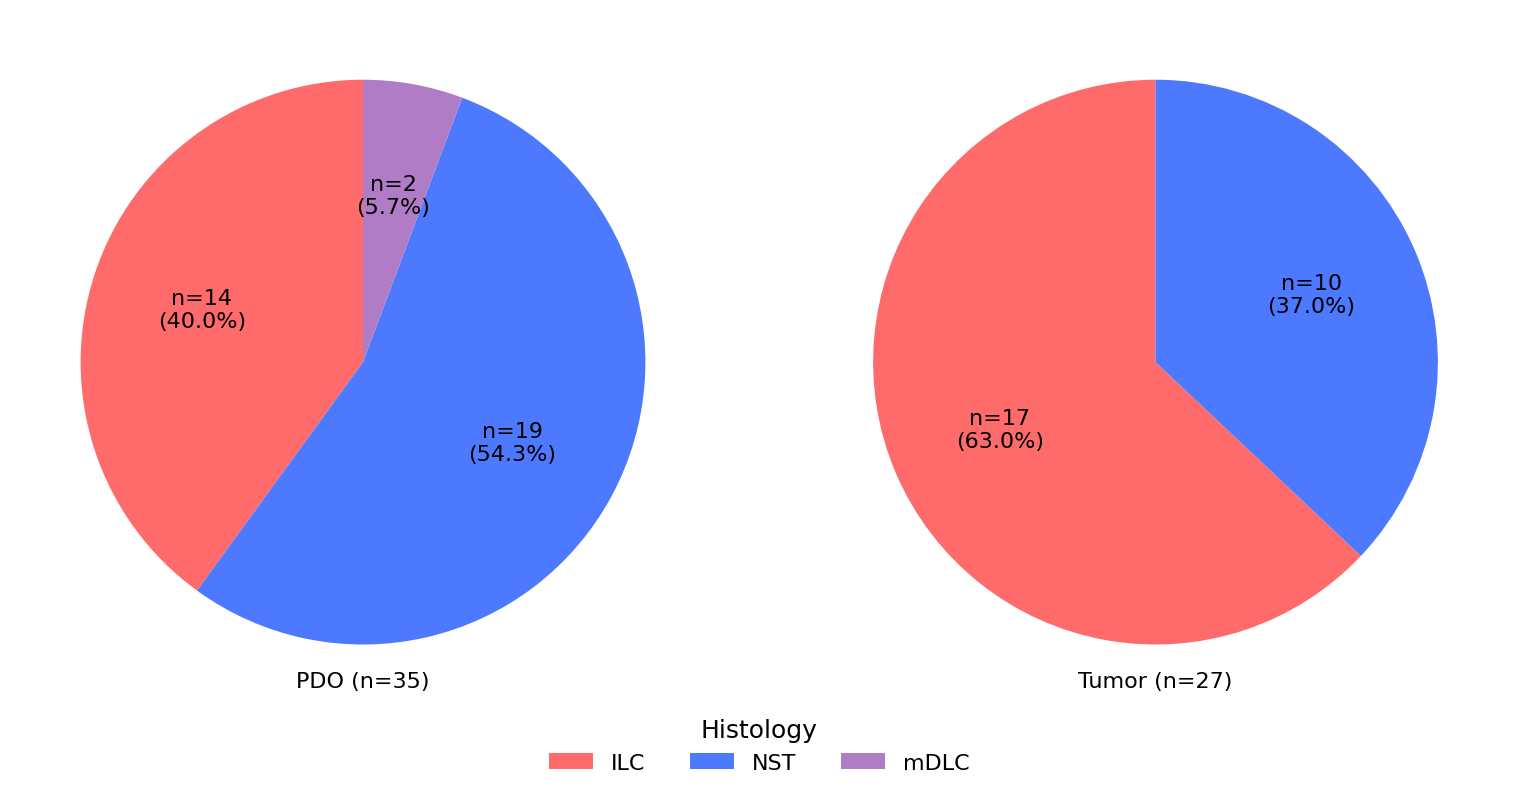


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Histology_pie.png
/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Histology_pie.pdf


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------
# Load data
# -----------------------------
csv_path = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical/Bionano_cohort.csv"
df = pd.read_csv(csv_path)

# Clean whitespace
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].astype(str).str.strip()

# -----------------------------
# Clean key columns
# -----------------------------
df["Histology"] = df["Histology"].astype(str).str.strip()
df["Origin"] = df["Origin"].astype(str).str.strip()

# Remove missing / empty Histology entries
df = df[
    df["Histology"].notna() &
    (df["Histology"] != "") &
    (df["Histology"].str.lower() != "nan")
].copy()

# -----------------------------
# Histology colors
# -----------------------------
color_map = {
    "ILC": "#FF6B6B",
    "NST": "#4D79FF",
    "mDLC": "#B07CC6"
}

# Fixed order in legend
histology_order = ["ILC", "NST", "mDLC"]

# Keep only histologies present in data
histology_order = [h for h in histology_order if h in df["Histology"].unique()]

# -----------------------------
# Count Histology function
# -----------------------------
def count_histology(df_subset):
    counts = (
        df_subset["Histology"]
        .astype(str)
        .str.strip()
        .value_counts()
    )
    counts = counts.reindex(histology_order, fill_value=0)
    counts = counts[counts > 0]
    return counts

# -----------------------------
# Autopct function
# -----------------------------
def autopct_with_counts(values):
    total = sum(values)

    def inner(pct):
        count = int(round(pct * total / 100.0))
        return f"n={count}\n({pct:.1f}%)" if count > 0 else ""
    return inner

# -----------------------------
# Split by Origin
# -----------------------------
pdo_df = df[df["Origin"] == "PDO"]
tumor_df = df[df["Origin"] == "Tumor"]

pdo_counts = count_histology(pdo_df)
tumor_counts = count_histology(tumor_df)

# -----------------------------
# Print sanity check
# -----------------------------
print("\nPDO histology counts:")
print(pdo_counts)

print("\nTumor histology counts:")
print(tumor_counts)

# -----------------------------
# Colors in plotted order
# -----------------------------
pdo_colors = [color_map[x] for x in pdo_counts.index]
tumor_colors = [color_map[x] for x in tumor_counts.index]

# -----------------------------
# Plot
# -----------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# PDO pie
axes[0].pie(
    pdo_counts,
    labels=None,
    colors=pdo_colors,
    autopct=autopct_with_counts(pdo_counts),
    startangle=90,
    textprops={"fontsize": 16},
    center=(0, 0.08)
)
# axes[0].set_title("Histology in PDO", fontsize=22, fontweight="bold", pad=10)
axes[0].text(0, -1.05, "PDO (n=35)", 
                 ha='center', va='center', fontsize=16)

# Tumor pie
axes[1].pie(
    tumor_counts,
    labels=None,
    colors=tumor_colors,
    autopct=autopct_with_counts(tumor_counts),
    startangle=90,
    textprops={"fontsize": 16},
    center=(0, 0.08)
)
# axes[1].set_title("Histology in Tumor", fontsize=22, fontweight="bold", pad=10)
axes[1].text(0, -1.05, "Tumor (n=27)", 
                 ha='center', va='center', fontsize=16)

# -----------------------------
# Shared legend
# -----------------------------
legend_handles = [
    Patch(facecolor=color_map[h], label=h)
    for h in histology_order
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=len(histology_order),
    fontsize=16,
    frameon=False,
    title="Histology",
    title_fontsize=18
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

# -----------------------------
# Save outputs
# -----------------------------
out_dir = "/ix1/alee/LO_LAB/Personal/Rahul/BioNano/Cohort/Clinical"
png_file = f"{out_dir}/Histology_pie.png"
pdf_file = f"{out_dir}/Histology_pie.pdf"

plt.savefig(png_file, dpi=300, bbox_inches="tight")
plt.savefig(pdf_file, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(png_file)
print(pdf_file)